# Shao–Wu: onde a `tanh` é necessária nos produtos de lags?

Comparamos **as mesmas árvores, coeficientes, condições iniciais e inovações** em quatro variantes: `all_tanh` (todos os lags), `no_tanh` (sem saturação), `product_lags` (cada fator antes de multiplicar), e `product_output` (o produto completo antes de aplicar uma única `tanh`). O caso com um único lag é o controle linear.

Para cada caso, usamos $x_t=s[c+b x_{t-5}+a\prod_{i=1}^k x_{t-\ell_i}]+\epsilon_t$. Para $k\geq2$, `product_lags` usa $a\prod_i\tanh(x_{t-\ell_i})$ e `product_output` usa $a\tanh(\prod_i x_{t-\ell_i})$. Os termos lineares permanecem livres nessas duas variantes. Para três ou quatro fatores, a nova variante calcula o produto completo e aplica `tanh` uma vez. A escala $s$ é **idêntica nas quatro variantes pareadas**, calculada pelas versões com limites finitos já disponíveis.

O teste matemático pergunta se o limite **global** da derivada em $\mathbb R^L$ é finito. Produtos de lags sem saturação têm limite infinito no domínio inteiro; isso impede usar este certificado global de Shao–Wu, mas não significa que toda trajetória finita exploda. O teste empírico pergunta outra coisa: quantas trajetórias cruzam o limiar operacional $|x|>100$ até 384 passos, em condições iniciais usuais e de estresse.

**Nova variante e a derivada:** para $f(u,v)=\tanh(uv)$, $\partial f/\partial u=v[1-\tanh^2(uv)]$. Em $u=0$, essa derivada é $v$, que pode crescer sem limite. Portanto, saída limitada e certificado global de contração são propriedades diferentes. Para fatores repetidos, como $\tanh(u^2)$, a derivada pode ser limitada, mas nosso cálculo conservador não reconhece essa identidade; a tabela marca apenas o que esse cálculo verifica.

**Fonte teórica:** Shao e Wu (2007), teorema 5.1, pp. 11–12, `https://arxiv.org/pdf/math/0611029`. A gramática, as transformações da AST e o teste de explosão são adaptações deste projeto.

In [1]:
from dataclasses import asdict
from pathlib import Path
from time import perf_counter
import hashlib, json, platform, sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'src' / 'tsfmxai').exists())
if str(ROOT / 'src') not in sys.path: sys.path.insert(0, str(ROOT / 'src'))
from tsfmxai.generators import (global_expression_bounds, saturate_all_lags,
    saturate_product_lags, saturate_product_outputs, simulate_innovation_path)
from tsfmxai.evaluation import StabilityDiagnosticConfig, diagnose_stability_prefixes, wilson_interval
from tsfmxai.representations import Add, Lag, MechanismBinding, Multiply, Parameter, Tanh, to_bound_formula, walk

SEED = 20261020
COUNT = 64  # trajetórias pareadas por caso e regime inicial
HORIZONS = (96, 192, 384)
NOISE_STD = .05
DIAG = StabilityDiagnosticConfig(HORIZONS, 100., 3 * NOISE_STD, 24)
COEFFICIENTS = {'a': 1.3, 'b': .15, 'c': .08}
INITIAL_LAWS = {'usual': (-1., 1.), 'stress': (2., 3.)}
VARIANTS = ('all_tanh', 'no_tanh', 'product_lags', 'product_output')
CASES = [(1, 'linear', (1,))]
for k in (2, 3, 4):
    CASES += [(k, 'same', (1,) * k), (k, 'distinct', tuple(range(1, k + 1)))]
    if k >= 3: CASES.append((k, 'mixed', (1, 1, 2) if k == 3 else (1, 1, 2, 2)))
print('cases:', CASES, '| trajectories per variant:', COUNT * len(CASES) * len(INITIAL_LAWS))

cases: [(1, 'linear', (1,)), (2, 'same', (1, 1)), (2, 'distinct', (1, 2)), (3, 'same', (1, 1, 1)), (3, 'distinct', (1, 2, 3)), (3, 'mixed', (1, 1, 2)), (4, 'same', (1, 1, 1, 1)), (4, 'distinct', (1, 2, 3, 4)), (4, 'mixed', (1, 1, 2, 2))] | trajectories per variant: 1152


Esta célula fixa a semente, os horizontes, o limiar de explosão e os padrões de lags. Para cada árvore, todas as variantes recebem exatamente as mesmas entradas aleatórias.


In [2]:
def product_tree(lags):
    term = Lag(0, 'l0')
    for i in range(1, len(lags)): term = Multiply(term, Lag(0, f'l{i}'))
    tree = Add(Add(Parameter('c'), Multiply(Parameter('b'), Lag(0, 'linear'))),
               Multiply(Parameter('a'), term))
    binding = MechanismBinding(COEFFICIENTS, {'linear': 5, **{f'l{i}': lag for i, lag in enumerate(lags)}})
    return tree, binding

def transformed_trees(tree):
    return {'all_tanh': saturate_all_lags(tree), 'no_tanh': tree,
            'product_lags': saturate_product_lags(tree),
            'product_output': saturate_product_outputs(tree)}

def global_gain(tree, binding):
    _, derivatives = global_expression_bounds(tree, binding, num_series=1, order=5)
    return float(np.sum(derivatives))

specifications = {}
certificate_rows = []
for k, pattern, lags in CASES:
    raw, binding = product_tree(lags)
    variants = transformed_trees(raw)
    pre = {name: global_gain(tree, binding) for name, tree in variants.items()}
    common_scale = min(.95, .76 / max(pre['all_tanh'], pre['product_lags']))
    scaled_binding = MechanismBinding({**COEFFICIENTS, 'scale': common_scale}, binding.lag_values)
    scaled = {name: Multiply(Parameter('scale'), tree) for name, tree in variants.items()}
    key = (k, pattern)
    specifications[key] = (lags, scaled, scaled_binding)
    for name, tree in scaled.items():
        gain = global_gain(tree, scaled_binding)
        certificate_rows.append(dict(k=k, pattern=pattern, variant=name, global_derivative_bound=gain,
                                     certified_global_gain=bool(np.isfinite(gain) and gain < 1),
                                     tanh_nodes=sum(isinstance(n, Tanh) for n in walk(tree)),
                                     common_scale=common_scale, formula=to_bound_formula(tree, scaled_binding)))
certificates = pd.DataFrame(certificate_rows)
assert certificates.query("variant in ['all_tanh', 'product_lags']").certified_global_gain.all()
assert certificates.query("k >= 2 and variant == 'no_tanh'").certified_global_gain.eq(False).all()
assert certificates.query("k == 1 and variant == 'product_lags'").tanh_nodes.eq(0).all()
display(certificates[['k','pattern','variant','global_derivative_bound','certified_global_gain','tanh_nodes','common_scale']])
for name in VARIANTS: print(name, ':', certificates[(certificates.k == 2) & (certificates.pattern == 'distinct') & (certificates.variant == name)].formula.iloc[0])

,k,pattern,variant,global_derivative_bound,certified_global_gain,tanh_nodes,common_scale
0,1,linear,all_tanh,0.76,True,2,0.524138
1,1,linear,no_tanh,0.76,True,0,0.524138
2,1,linear,product_lags,0.76,True,0,0.524138
3,1,linear,product_output,0.76,True,0,0.524138
4,2,same,all_tanh,0.76,True,3,0.276364
5,2,same,no_tanh,inf,False,0,0.276364
6,2,same,product_lags,0.76,True,2,0.276364
7,2,same,product_output,inf,False,1,0.276364
8,2,distinct,all_tanh,0.76,True,3,0.276364
9,2,distinct,no_tanh,inf,False,0,0.276364


all_tanh : (0.276364 * ((0.08 + (0.15 * tanh(x_0(t-5)))) + (1.3 * (tanh(x_0(t-1)) * tanh(x_0(t-2))))))
no_tanh : (0.276364 * ((0.08 + (0.15 * x_0(t-5))) + (1.3 * (x_0(t-1) * x_0(t-2)))))
product_lags : (0.276364 * ((0.08 + (0.15 * x_0(t-5))) + (1.3 * (tanh(x_0(t-1)) * tanh(x_0(t-2))))))
product_output : (0.276364 * ((0.08 + (0.15 * x_0(t-5))) + (1.3 * tanh((x_0(t-1) * x_0(t-2))))))


A tabela calcula um limite conservador para a soma das derivadas em relação ao histórico. `∞` para o produto não saturado significa ausência de **certificado global por esta regra**, não uma afirmação de explosão inevitável. O termo linear adicional permanece sem `tanh` somente na variante seletiva.


In [3]:
rows, representative = [], {}
runtime = {variant: 0. for variant in VARIANTS}
for case_index, (k, pattern, lags) in enumerate(CASES):
    _, trees, binding = specifications[(k, pattern)]
    for law_index, (law, (lo, hi)) in enumerate(INITIAL_LAWS.items()):
        for replicate in range(COUNT):
            rng = np.random.default_rng(np.random.SeedSequence([SEED, case_index, law_index, replicate]))
            history = rng.uniform(lo, hi, size=(1, 5))
            innovations = rng.normal(0., NOISE_STD, size=(1, max(HORIZONS)))
            for variant in VARIANTS:
                start = perf_counter()
                path = simulate_innovation_path((trees[variant],), (binding,), history, innovations,
                                                stop_threshold=DIAG.explosion_limit)
                runtime[variant] += perf_counter() - start
                checks = diagnose_stability_prefixes(path[0], DIAG)
                for check in checks:
                    rows.append(dict(k=k, pattern=pattern, initial_law=law, replicate=replicate,
                                     variant=variant, horizon=check.horizon, exploded=check.exploded,
                                     near_zero=check.near_zero, explosion_step=check.explosion_step))
                if k == 4 and pattern == 'same' and law == 'stress' and replicate == 0:
                    representative[variant] = (history.copy(), path.copy())
outcomes = pd.DataFrame(rows)
summary = outcomes.groupby(['k','pattern','initial_law','variant','horizon'], sort=False).agg(
    trajectories=('replicate','size'), explosions=('exploded','sum'), near_zero=('near_zero','sum')).reset_index()
summary['explosion_pct'] = 100 * summary.explosions / summary.trajectories
summary['near_zero_pct'] = 100 * summary.near_zero / summary.trajectories
summary['explosion_wilson_95'] = [tuple(round(100*x, 1) for x in wilson_interval(int(a), int(b)))
                                   for a,b in zip(summary.explosions, summary.trajectories)]
display(summary.query('horizon == 384')[['k','pattern','initial_law','variant','explosions','explosion_pct',
                                           'explosion_wilson_95','near_zero_pct']])
print('Trajectory-execution seconds (one serial run; excludes case preparation):', runtime)

,k,pattern,initial_law,variant,explosions,explosion_pct,explosion_wilson_95,near_zero_pct
2,1,linear,usual,all_tanh,0,0.0,"(0.0, 5.7)",0.000
5,1,linear,usual,no_tanh,0,0.0,"(0.0, 5.7)",0.000
8,1,linear,usual,product_lags,0,0.0,"(0.0, 5.7)",0.000
11,1,linear,usual,product_output,0,0.0,"(0.0, 5.7)",0.000
14,1,linear,stress,all_tanh,0,0.0,"(0.0, 5.7)",0.000
...,...,...,...,...,...,...,...,...
203,4,mixed,usual,product_output,0,0.0,"(0.0, 5.7)",90.625
206,4,mixed,stress,all_tanh,0,0.0,"(0.0, 5.7)",93.750
209,4,mixed,stress,no_tanh,64,100.0,"(94.3, 100.0)",0.000
212,4,mixed,stress,product_lags,0,0.0,"(0.0, 5.7)",93.750


Trajectory-execution seconds (one serial run; excludes case preparation): {'all_tanh': 16.69796649669297, 'no_tanh': 8.509962901240215, 'product_lags': 15.56055860221386, 'product_output': 14.11390110035427}


Este é o teste de trajetórias: para cada par árvore–histórico–ruído, variamos apenas a posição da `tanh`. A condição de estresse usa valores iniciais positivos entre 2 e 3 para revelar trajetórias potencialmente divergentes; ela **não** é a lei inicial padrão do gerador. A porcentagem observada é uma medida finita, com intervalo de Wilson para a taxa de explosão.


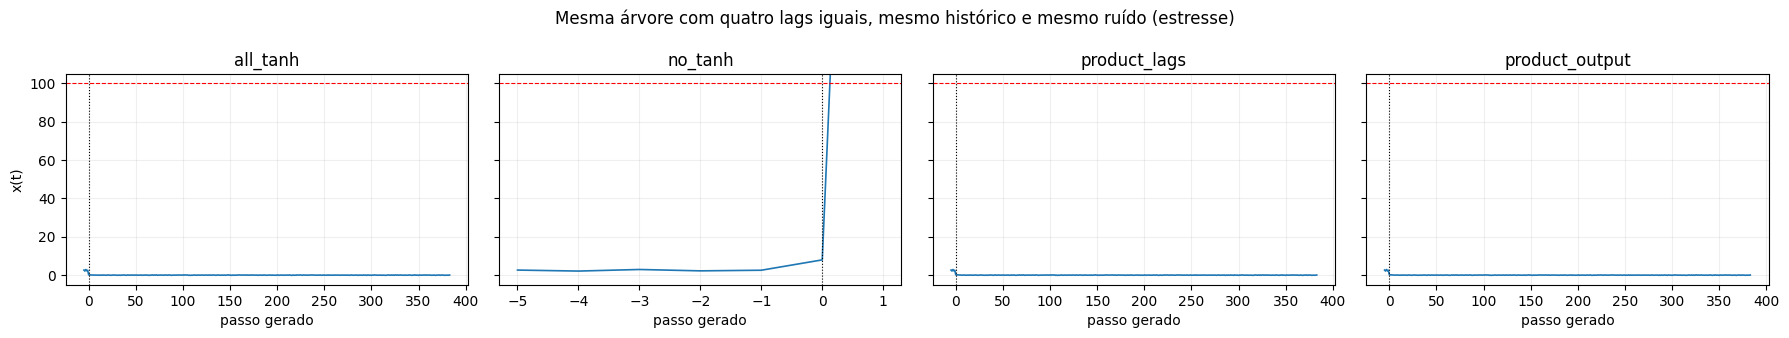

variant                 all_tanh   no_tanh  product_lags  product_output
k pattern  initial_law                                                  
1 linear   stress            0.0    0.0000           0.0             0.0
           usual             0.0    0.0000           0.0             0.0
2 distinct stress            0.0   17.1875           0.0             0.0
           usual             0.0    0.0000           0.0             0.0
  same     stress            0.0   25.0000           0.0             0.0
           usual             0.0    0.0000           0.0             0.0
3 distinct stress            0.0  100.0000           0.0             0.0
           usual             0.0    0.0000           0.0             0.0
  mixed    stress            0.0  100.0000           0.0             0.0
           usual             0.0    0.0000           0.0             0.0
  same     stress            0.0  100.0000           0.0             0.0
           usual             0.0    0.0000           0.0             0.0
4 distinct stress            0.0  100.0000           0.0             0.0
           usual             0.0    0.0000           0.0             0.0
  mixed    stress            0.0  100.0000           0.0             0.0
           usual             0.0    0.0000           0.0             0.0
  same     stress            0.0  100.0000           0.0             0.0
           usual             0.0    0.0000           0.0             0.0

In [4]:
fig, axes = plt.subplots(1, len(VARIANTS), figsize=(18, 3.4), sharey=True)
for ax, variant in zip(axes, VARIANTS):
    history, path = representative[variant]
    values = np.r_[history[0], path[0]]
    ax.plot(np.arange(-5, len(path[0])), values, lw=1.2)
    ax.axhline(100, color='red', ls='--', lw=.8)
    ax.axvline(0, color='black', ls=':', lw=.8)
    ax.set(title=variant, xlabel='passo gerado', ylim=(-5, 105))
    ax.grid(alpha=.2)
axes[0].set_ylabel('x(t)')
fig.suptitle('Mesma árvore com quatro lags iguais, mesmo histórico e mesmo ruído (estresse)')
fig.tight_layout()
plt.show()
display(summary.query('horizon == 384').pivot_table(index=['k','pattern','initial_law'],
        columns='variant', values='explosion_pct'))

A figura mostra um exemplo pareado, e a tabela final compara todas as combinações. A transformação seletiva preserva o termo linear sem saturação, mas limita os fatores do produto. Nenhum resultado empírico de 384 passos prova ausência de explosões em todos os tempos.


In [5]:
from dataclasses import replace
from tsfmxai.generators import (RandomTreeConfig, ShaoWuConfig, sample_shao_wu_mechanisms,
                                 SampledMechanism, sample_random_mechanism)
from tsfmxai.evaluation.generator_tradeoff import benchmark_stability_method
RANDOM_COUNT = 1000
BASE_TREE = RandomTreeConfig(minimum_operators=1, maximum_operators=6,
    num_series=1, minimum_lag=1, maximum_lag=12, parameter_probability=.55,
    time_probability=0., lag_probability=.45, add_probability=.8,
    minimum_parameter_magnitude=.05, maximum_parameter_magnitude=.8,
    require_lag=True, require_time=False, coefficient_gate_lags=False)
RANDOM_CONFIG = ShaoWuConfig(tree_config=BASE_TREE, innovation_std=NOISE_STD, target_gain=.8)
RANDOM_VARIANTS = {'all_tanh': 'tanh', 'no_tanh': 'identity',
                   'product_lags': 'product_lags', 'product_output': None}
random_comparison = []
for variant, transform in RANDOM_VARIANTS.items():
    started = perf_counter()
    if variant == 'product_output':
        reference = sample_shao_wu_mechanisms(replace(RANDOM_CONFIG, lag_transform='product_lags'),
                                              root_seed=SEED, count=RANDOM_COUNT)
        mechanisms = []
        for ref in reference:
            base = sample_random_mechanism(BASE_TREE, seed=ref.seed, sample_index=ref.sample_index)
            tree = Multiply(Parameter('PRODUCT_OUTPUT_SCALE'), saturate_product_outputs(base.expression))
            binding = MechanismBinding({**base.binding.parameter_values, 'PRODUCT_OUTPUT_SCALE': ref.scale},
                                       base.binding.lag_values)
            mechanisms.append(SampledMechanism(tree, binding, ref.seed, ref.sample_index))
    else:
        mechanisms = sample_shao_wu_mechanisms(replace(RANDOM_CONFIG, lag_transform=transform),
                                               root_seed=SEED, count=RANDOM_COUNT)
    sample_time = perf_counter() - started  # inclui todas as propostas rejeitadas
    rejected = sum(getattr(m, 'proposal_attempt', 0) for m in mechanisms)
    evaluated = benchmark_stability_method(variant, mechanisms, root_seed=SEED,
        diagnostic_config=DIAG, innovation_std=NOISE_STD,
        sampling_seconds=sample_time, keep_examples=0)
    full = [r for r in evaluated['outcomes'] if r['horizon'] == 384]
    random_comparison.append(dict(variant=variant, mechanisms=RANDOM_COUNT,
        rejected_proposals=rejected, acceptance_fraction=RANDOM_COUNT/(RANDOM_COUNT+rejected),
        sampling_seconds=sample_time, mechanisms_per_second=RANDOM_COUNT/sample_time,
        explosions=sum(r['exploded'] for r in full),
        near_zero=sum(r['near_zero'] for r in full),
        tanh_tree_fraction=np.mean([any(isinstance(n, Tanh) for e in
                                         (m.expressions if hasattr(m, 'expressions') else (m.expression,))
                                         for n in walk(e)) for m in mechanisms]),
        total_seconds=evaluated['performance']['total_seconds'],
        global_contraction_certificate=variant != 'product_output'))
random_summary = pd.DataFrame(random_comparison)
random_summary['explosion_pct'] = 100*random_summary.explosions/RANDOM_COUNT
random_summary['near_zero_pct'] = 100*random_summary.near_zero/RANDOM_COUNT
display(random_summary)
print('Identical root seeds pair the first raw proposal for all_tanh/product_lags,',
      'but not identity samples after rejection. Their post-certificate scales also differ.')

,variant,mechanisms,rejected_proposals,acceptance_fraction,sampling_seconds,mechanisms_per_second,explosions,near_zero,tanh_tree_fraction,total_seconds,global_contraction_certificate,explosion_pct,near_zero_pct
0,all_tanh,1000,0,1.000000,0.933037,1071.768743,0,237,1.000,12.972779,True,0.0,23.7
1,no_tanh,1000,253,0.798085,1.092652,915.204140,0,133,0.000,11.064373,True,0.0,13.3
2,product_lags,1000,0,1.000000,0.943862,1059.476354,0,235,0.209,14.650229,True,0.0,23.5
3,product_output,1000,0,1.000000,2.213044,451.866359,0,235,0.209,13.793067,False,0.0,23.5


Identical root seeds pair the first raw proposal for all_tanh/product_lags, but not identity samples after rejection. Their post-certificate scales also differ.


A tabela reúne quatro variantes. As três anteriores usam seus amostradores; `product_output` recupera a mesma árvore bruta e usa a escala da referência `product_lags`, mantendo o histórico e o ruído pareados com ela. Essa escala pertence à referência e não certifica a nova fórmula. O tempo inclui esse preparo extra, rejeições quando existentes e cálculo da escala. O sampler sem `tanh` pode trocar árvores após rejeição.


In [6]:
# Registro completo do experimento: pergunta, configuração, proveniência, métricas e reprodução.
source_paths = ('src/tsfmxai/generators/shao_wu.py', 'src/tsfmxai/generators/random_expression.py',
                'src/tsfmxai/generators/stochastic.py',
                'src/tsfmxai/evaluation/stability.py', 'src/tsfmxai/evaluation/generator_tradeoff.py')
comparison = summary.query('horizon == 384').to_dict(orient='records')
record = {
 'experiment_id': 'shao_wu_product_lag_ablation_001',
 'research_question': 'Em produtos de dois a quatro lags, quais lags precisam de tanh para o certificado global e qual é o efeito observado na explosão?',
 'hypothesis': 'Saturar somente lags que participam de produtos não lineares preserva o limite global sem saturar o termo linear; o produto cru perde o certificado e pode explodir sob inicialização de estresse.',
 'configuration': {'seed': SEED, 'trajectories_per_case_law_variant': COUNT, 'cases': CASES,
                   'horizons': HORIZONS, 'diagnostics': asdict(DIAG), 'innovation_std': NOISE_STD,
                   'base_coefficients': COEFFICIENTS, 'initial_laws': INITIAL_LAWS,
                   'scaling': 'same min(.95, .76/max(reference finite derivative bounds)) in all four paired variants; random product_output borrows the product_lags reference scale',
                   'random_sampler_count_per_variant': RANDOM_COUNT,
                   'random_sampler_tree': asdict(BASE_TREE),
                   'random_sampler_config': asdict(RANDOM_CONFIG)},
 'provenance': {'python': platform.python_version(), 'numpy': np.__version__,
                'pandas': pd.__version__, 'source_sha256':
                {p: hashlib.sha256((ROOT / p).read_bytes()).hexdigest() for p in source_paths}},
 'seed_usage': 'SeedSequence([SEED, case_index, law_index, replicate]); same sampled history/noise reused by all variants',
 'metrics': {'certificate': certificates.to_dict(orient='records'),
             'horizon_384': comparison, 'trajectory_execution_seconds': runtime,
             'random_sampler': random_summary.to_dict(orient='records')},
 'scientific_summary': 'Four variants compare saturation of all lags, no saturation, saturation of each product factor, and saturation after the entire product. Product-output saturation is empirically evaluated without a global contraction certificate. Paired and random results, including near-zero counts and preparation time, are recorded above.',
 'limitations': ['The operational explosion threshold and 384-step horizon do not establish mathematical necessity of tanh.',
                 'Identity products are run without the production identity sampler rejection filter, intentionally to expose their behavior.',
                 'Initial stress histories are a diagnostic intervention, not the production initialization law.',
                 'The finite derivative bound is sufficient and conservative; other stabilization mechanisms may exist.',
                 'Runtime is one serial execution, not a calibrated timing interval.',
                 'Product-output preparation includes constructing a reference to reuse its scale; the transformed expression inherits no reference certificate.',
                 'The production identity sampler changes raw trees after rejection; its comparison is not paired.'],
 'reproduction_command': r'.\.venv\Scripts\python.exe -m jupyter nbconvert --to notebook --execute --inplace experiments/abstract_syntax_tree/shao_wu_selective_tanh/00_product_lag_ablation.ipynb',
}
print(json.dumps(record, indent=2, default=str))

{
  "experiment_id": "shao_wu_product_lag_ablation_001",
  "research_question": "Em produtos de dois a quatro lags, quais lags precisam de tanh para o certificado global e qual \u00e9 o efeito observado na explos\u00e3o?",
  "hypothesis": "Saturar somente lags que participam de produtos n\u00e3o lineares preserva o limite global sem saturar o termo linear; o produto cru perde o certificado e pode explodir sob inicializa\u00e7\u00e3o de estresse.",
  "configuration": {
    "seed": 20261020,
    "trajectories_per_case_law_variant": 64,
    "cases": [
      [
        1,
        "linear",
        [
          1
        ]
      ],
      [
        2,
        "same",
        [
          1,
          1
        ]
      ],
      [
        2,
        "distinct",
        [
          1,
          2
        ]
      ],
      [
        3,
        "same",
        [
          1,
          1,
          1
        ]
      ],
      [
        3,
        "distinct",
        [
          1,
          2,
        

**Registro completo do experimento:** a célula anterior contém pergunta, hipótese, configuração, proveniência, sementes, métricas, síntese, limitações e comando de reprodução. Não há arquivos de resultados paralelos a este notebook executado.
